
# Support-Conditioned Initialization for Few-Shot Personalization in Low-Rank Reward Models (LoRe)

## Abstract
We investigate methods for accelerating few-shot preference personalization in Low-Rank Reward Models (LoRe). By utilizing the preference distributions of a previously observed population, we construct support-conditioned initialization strategies that bypass or accelerate early-stage gradient adaptation. We compare five initialization methods across three support sizes ($N \in \{16, 50, 150\}$) and evaluate their query-set generalization trajectories over five experimental seeds.

In [ ]:
# ============================================================
# CELL 0: ENVIRONMENT SETUP
# ============================================================

import os
import gc
import random
import time

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from pathlib import Path
from safetensors.torch import load_file
from sklearn.cluster import KMeans
from google.colab import drive

drive.mount("/content/drive")

# Reproducibility
SEEDS = [42, 43, 44, 45, 46]

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

DEVICE = torch.device("cpu")
torch.set_num_threads(2)

# Directories
BASE_DIR = Path("/content/drive/MyDrive/LoRe")

EMBEDDING_DIR = BASE_DIR / "PersonalLLM_embeddings"

RUN_DIR = BASE_DIR / "PersonalLLM_runs"

CKPT_DIR = (
    RUN_DIR /
    "K5_alpha_sweep_5seeds_joint2000_fewshot1000"
)

OUTPUT_DIR = (
    BASE_DIR /
    "FewShot_Initialization" /
    "PersonalLLM_v2"
)

RESULTS_DIR = OUTPUT_DIR / "results"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# Experiment configuration
D = 4096
K = 5

NUM_SEEN_USERS = 1000
NUM_UNSEEN_USERS = 500

SUPPORT_SIZES = [15, 50, 150]
UPDATE_BUDGETS = [5, 20, 50]

NUM_ADAPTATION_STEPS = 50
ADAPTATION_LR = 0.1
SCORE_SCALE = 100.0

INITIALIZATION_METHODS = [
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

print("Environment initialized.")
print("Device:", DEVICE)
print("Seeds:", SEEDS)
print("Checkpoint directory:", CKPT_DIR)
print("Output directory:", OUTPUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Environment initialized.
Device: cpu
Seeds: [42, 43, 44, 45, 46]
Checkpoint directory: /content/drive/MyDrive/LoRe/PersonalLLM_runs/K5_alpha_sweep_5seeds_joint2000_fewshot1000
Output directory: /content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2


In [ ]:
# ============================================================
# CELL 1: VERIFY ORIGINAL PERSONAL LLM CHECKPOINTS
# ============================================================

CKPT_DIR = (
    BASE_DIR
    / "PersonalLLM_runs"
    / "K5_alpha_sweep_5seeds_joint2000_fewshot1000"
)

print("CHECKPOINT INVENTORY")
print("=" * 70)

for seed in SEEDS:

    path = CKPT_DIR / f"alpha_0p1_seed_{seed}.pt"

    print(
        f"Seed {seed}:",
        "FOUND" if path.exists() else "MISSING"
    )

    if path.exists():
        print(f"  Size: {path.stat().st_size / (1024**2):.2f} MB")

# Inspect seed 42
seed42_path = CKPT_DIR / "alpha_0p1_seed_42.pt"

assert seed42_path.exists(), (
    "Original seed 42 checkpoint not found."
)

ckpt = torch.load(
    seed42_path,
    map_location="cpu",
    weights_only=False
)

print("\nCHECKPOINT CONTENTS")
print("=" * 70)

for key, value in ckpt.items():

    if isinstance(value, torch.Tensor):
        print(key, tuple(value.shape), value.dtype)

    elif isinstance(value, dict):
        print(key, value)

    else:
        print(key, type(value).__name__)

CHECKPOINT INVENTORY
Seed 42: FOUND
  Size: 0.52 MB
Seed 43: FOUND
  Size: 0.52 MB
Seed 44: FOUND
  Size: 0.52 MB
Seed 45: FOUND
  Size: 0.52 MB
Seed 46: FOUND
  Size: 0.52 MB

CHECKPOINT CONTENTS
config {'run_id': 'alpha_0p1_seed_42', 'seed': 42, 'dirichlet_alpha': 0.1, 'K': 5, 'n_seen_users': 1000, 'n_unseen_users': 500, 'seen_pairs_per_user': 47, 'fewshot_pairs_per_user': 9, 'joint_steps': 2000, 'fewshot_steps': 1000, 'regularization_alpha': 0.0, 'seen_train_mean_pct': np.float32(99.83191), 'seen_train_user_sd_pct': np.float32(0.7515157), 'seen_test_mean_pct': np.float64(95.29590452313424), 'seen_test_user_sd_pct': np.float64(5.855919800916472), 'fewshot_train_mean_pct': np.float32(98.86667), 'fewshot_train_user_sd_pct': np.float32(4.494111), 'unseen_test_mean_pct': np.float64(94.21980440616608), 'unseen_test_user_sd_pct': np.float64(6.918612071846921), 'runtime_seconds': 6.564487457275391, 'final_joint_loss': 12.233036041259766, 'final_fewshot_loss': 16.29153823852539}
V (4096, 5) 


## 1. Experimental Background & Verification
We reuse the learned 5-dimensional reward bases ($K=5$) and preference profiles from the original five jointly trained LoRe checkpoints (Seeds 42–46). The original dataset features $1,000$ seen users and $500$ unseen users.

Before executing the initialization sweeps, we verify that our local environment successfully loads the original checkpoints and perfectly reproduces the baseline unseen-user evaluation scores, confirming a zero-mismatch reproduction framework.

In [ ]:
# ============================================================
# CELL 2: LOAD ORIGINAL EMBEDDINGS, REWARD SCORES AND CHECKPOINTS
# ============================================================

from safetensors.torch import load_file

# ------------------------------------------------------------
# 1. LOAD REWARD SCORES AND MODEL NAMES
# ------------------------------------------------------------

reward_data = np.load(EMBEDDING_DIR / "reward_scores.npz")

TRAIN_SCORES = torch.from_numpy(
    reward_data["train_scores"]
).float()

TEST_SCORES = torch.from_numpy(
    reward_data["test_scores"]
).float()

MODEL_NAMES = reward_data["model_names"]

# Verify reward-model ordering.
EXPECTED_MODELS = [
    "gemma_2b",
    "gemma_7b",
    "mistral_raft",
    "llama3_sfairx",
    "oasst_deberta_v3",
    "beaver_7b",
    "oasst_pythia_7b",
    "oasst_pythia_1b",
    "mistral_ray",
    "mistral_weqweasdas",
]

loaded_models = [
    x.decode() if isinstance(x, (bytes, np.bytes_)) else str(x)
    for x in MODEL_NAMES
]

assert loaded_models == EXPECTED_MODELS, (
    f"Reward model ordering mismatch: {loaded_models}"
)

# ------------------------------------------------------------
# 2. LOAD EMBEDDINGS
# ------------------------------------------------------------

TRAIN_EMB = load_file(
    str(EMBEDDING_DIR / "train.safetensors")
)["embeddings"].reshape(9402, 8, 4096).contiguous()

TEST_EMB = load_file(
    str(EMBEDDING_DIR / "test.safetensors")
)["embeddings"].reshape(1000, 8, 4096).contiguous()

# ------------------------------------------------------------
# 3. VERIFY DATA DIMENSIONS
# ------------------------------------------------------------

assert TRAIN_EMB.shape == (9402, 8, 4096)
assert TEST_EMB.shape == (1000, 8, 4096)

assert TRAIN_SCORES.shape == (9402, 8, 10)
assert TEST_SCORES.shape == (1000, 8, 10)

# ------------------------------------------------------------
# 4. LOAD ORIGINAL CHECKPOINTS
# ------------------------------------------------------------

CKPT_DIR = (
    BASE_DIR / "PersonalLLM_runs"
    / "K5_alpha_sweep_5seeds_joint2000_fewshot1000"
)

ORIGINAL_CKPTS = {}

print("ORIGINAL CHECKPOINTS")
print("=" * 75)

for seed in SEEDS:

    path = CKPT_DIR / f"alpha_0p1_seed_{seed}.pt"

    assert path.exists(), f"Missing checkpoint for seed {seed}"

    ckpt = torch.load(
        path,
        map_location="cpu",
        weights_only=False
    )

    assert ckpt["V"].shape == (4096, 5)
    assert ckpt["W_seen_fit"].shape == (1000, 5)
    assert ckpt["W_unseen_fit"].shape == (500, 5)

    assert ckpt["seen_prompt_indices"].shape == (1000, 47)
    assert ckpt["fewshot_prompt_indices"].shape == (500, 9)

    assert torch.allclose(
        ckpt["W_seen_fit"].sum(dim=1),
        torch.ones(1000),
        atol=1e-5
    )

    assert torch.allclose(
        ckpt["W_unseen_fit"].sum(dim=1),
        torch.ones(500),
        atol=1e-5
    )

    ORIGINAL_CKPTS[seed] = ckpt

    config = ckpt["config"]

    print(
        f"Seed {seed}: "
        f"Seen={config['seen_test_mean_pct']:.2f}% | "
        f"Unseen={config['unseen_test_mean_pct']:.2f}%"
    )

# ------------------------------------------------------------
# 5. FINAL VERIFICATION
# ------------------------------------------------------------

print("\nALL ORIGINAL ARTIFACTS LOADED AND VERIFIED")
print("=" * 75)

print("Train embeddings:", tuple(TRAIN_EMB.shape))
print("Test embeddings: ", tuple(TEST_EMB.shape))
print("Train scores:", tuple(TRAIN_SCORES.shape))
print("Test scores:", tuple(TEST_SCORES.shape))
print("Model ordering: verified")
print("Checkpoints loaded:", len(ORIGINAL_CKPTS))

ORIGINAL CHECKPOINTS
Seed 42: Seen=95.30% | Unseen=94.22%
Seed 43: Seen=95.69% | Unseen=94.50%
Seed 44: Seen=95.79% | Unseen=93.94%
Seed 45: Seen=95.79% | Unseen=95.01%
Seed 46: Seen=95.60% | Unseen=94.64%

ALL ORIGINAL ARTIFACTS LOADED AND VERIFIED
Train embeddings: (9402, 8, 4096)
Test embeddings:  (1000, 8, 4096)
Train scores: (9402, 8, 10)
Test scores: (1000, 8, 10)
Model ordering: verified
Checkpoints loaded: 5



## 2. Dataset Construction & Feature Projection
For each prompt, eight candidate responses are scored via the ground-truth 10-dimensional user reward preferences. The highest-scoring and lowest-scoring candidates are identified to construct a personalized best-versus-worst comparison pair.

The difference between the chosen and rejected response embeddings is projected through the frozen 5-dimensional reward basis ($V \in \mathbb{R}^{4096 \times 5}$), yielding a low-rank feature vector:

$$z_i = (x_{chosen} - x_{rejected}) V \in \mathbb{R}^{5}$$

For each unseen user, we build nested support sets ($N=16$, $N=50$, $N=150$) by appending additional distinct training prompts onto the original $9$ few-shot training prompts. Generalization performance is evaluated on a fixed, identical set of $1,000$ held-out query prompts per user.


In [ ]:
# ============================================================
# CELL 4: CONSTRUCT NESTED UNSEEN-USER SUPPORT SETS
# ============================================================

SUPPORT_SIZES = [16, 50, 150]
MAX_SUPPORT = max(SUPPORT_SIZES)

SUPPORT_INDICES = {}

for seed in SEEDS:

    ckpt = ORIGINAL_CKPTS[seed]

    # The exact 9 prompts used in the original experiment.
    original_indices = np.asarray(
        ckpt["fewshot_prompt_indices"],
        dtype=np.int64
    )

    assert original_indices.shape == (500, 9)

    support_indices = np.empty(
        (NUM_UNSEEN_USERS, MAX_SUPPORT),
        dtype=np.int64
    )

    for user_idx in range(NUM_UNSEEN_USERS):

        original = original_indices[user_idx]

        assert len(np.unique(original)) == 9

        # Sample additional prompts without replacing the original 9.
        available = np.setdiff1d(
            np.arange(TRAIN_SCORES.shape[0]),
            original
        )

        rng = np.random.default_rng(
            10_000_000 + seed * 1000 + user_idx
        )

        additional = rng.choice(
            available,
            size=MAX_SUPPORT - len(original),
            replace=False
        )

        support_indices[user_idx] = np.concatenate(
            [original, additional]
        )

    # Verify uniqueness and nested support sets.
    for user_idx in range(NUM_UNSEEN_USERS):

        assert len(np.unique(support_indices[user_idx])) == MAX_SUPPORT

        for n in SUPPORT_SIZES:
            assert np.array_equal(
                support_indices[user_idx, :n],
                support_indices[user_idx, :n]
            )

    SUPPORT_INDICES[seed] = support_indices

    print(
        f"Seed {seed}: "
        f"original={original_indices.shape[1]}, "
        f"support sets={support_indices.shape}"
    )

# Save the exact support assignments.
save_dict = {}

for seed in SEEDS:
    for n in SUPPORT_SIZES:
        save_dict[f"seed_{seed}_N_{n}"] = (
            SUPPORT_INDICES[seed][:, :n]
        )

np.savez_compressed(
    OUTPUT_DIR / "support_prompt_indices.npz",
    **save_dict
)

print("\nAll support sets constructed.")
print("Nested support assignments saved.")

Seed 42: original=9, support sets=(500, 150)
Seed 43: original=9, support sets=(500, 150)
Seed 44: original=9, support sets=(500, 150)
Seed 45: original=9, support sets=(500, 150)
Seed 46: original=9, support sets=(500, 150)

All support sets constructed.
Nested support assignments saved.


In [ ]:
# ============================================================
# CELL 5: BUILD PROJECTED SUPPORT AND QUERY FEATURES
# ============================================================

D = 4096
K = 5
BATCH_SIZE = 8

SUPPORT_FEATURES = {}
QUERY_FEATURES = {}

def build_projected_features(
    scores,
    embeddings,
    true_weights,
    prompt_indices,
    V,
    batch_size=8
):
    """
    Generate original best-versus-worst embedding differences,
    then project them into the frozen 5-dimensional reward basis.
    """

    n_users, n_examples = prompt_indices.shape

    Z = torch.empty(
        (n_users, n_examples, K),
        dtype=torch.float32
    )

    scores = scores.cpu()
    embeddings = embeddings.cpu()
    true_weights = true_weights.cpu().float()
    V = V.cpu().float()

    for start in range(0, n_users, batch_size):

        end = min(start + batch_size, n_users)

        prompt_idx = torch.as_tensor(
            prompt_indices[start:end],
            dtype=torch.long
        )

        user_weights = true_weights[start:end]

        # Generate personalized best-versus-worst labels.
        selected_scores = scores[prompt_idx]

        candidate_scores = torch.einsum(
            "bnrm,bm->bnr",
            selected_scores,
            user_weights
        )

        chosen_idx = candidate_scores.argmax(dim=-1)
        rejected_idx = candidate_scores.argmin(dim=-1)

        # Subtract in the original embedding dtype before FP32 casting.
        chosen_emb = embeddings[prompt_idx, chosen_idx]
        rejected_emb = embeddings[prompt_idx, rejected_idx]

        differences = (chosen_emb - rejected_emb).float()

        # Frozen basis projection.
        projected = (
            differences.reshape(-1, D) @ V
        ).reshape(end - start, n_examples, K)

        Z[start:end] = projected

    return Z


for seed in SEEDS:

    print(f"\nProcessing seed {seed}...")

    ckpt = ORIGINAL_CKPTS[seed]

    V = ckpt["V"].float()

    W_unseen_true = torch.as_tensor(
        ckpt["W_unseen_true"],
        dtype=torch.float32
    )

    W_unseen_fit = ckpt["W_unseen_fit"].float()

    # Build the maximum support set once.
    Z_support = build_projected_features(
        TRAIN_SCORES,
        TRAIN_EMB,
        W_unseen_true,
        SUPPORT_INDICES[seed],
        V,
        BATCH_SIZE
    )

    # All 1,000 held-out test prompts for every unseen user.
    query_indices = np.tile(
        np.arange(TEST_SCORES.shape[0]),
        (NUM_UNSEEN_USERS, 1)
    )

    Z_query = build_projected_features(
        TEST_SCORES,
        TEST_EMB,
        W_unseen_true,
        query_indices,
        V,
        BATCH_SIZE
    )

    # Validate against the original checkpoint.
    query_margins = (
        Z_query * W_unseen_fit[:, None, :]
    ).sum(dim=-1)

    reproduced_accuracy = (
        (query_margins > 0).float().mean().item() * 100
    )

    expected_accuracy = float(
        ckpt["config"]["unseen_test_mean_pct"]
    )

    difference = reproduced_accuracy - expected_accuracy

    assert abs(difference) < 0.001, (
        f"Seed {seed}: accuracy mismatch "
        f"{reproduced_accuracy:.5f}% vs {expected_accuracy:.5f}%"
    )

    SUPPORT_FEATURES[seed] = Z_support
    QUERY_FEATURES[seed] = Z_query

    np.savez_compressed(
        OUTPUT_DIR / f"projected_features_seed_{seed}.npz",
        support=Z_support.numpy(),
        query=Z_query.numpy()
    )

    print(f"Support features: {tuple(Z_support.shape)}")
    print(f"Query features:   {tuple(Z_query.shape)}")
    print(f"Original accuracy:  {expected_accuracy:.4f}%")
    print(f"Reproduced accuracy: {reproduced_accuracy:.4f}%")
    print(f"Difference: {difference:+.6f} pp")

print("\nALL FIVE SEEDS VALIDATED.")


Processing seed 42...
Support features: (500, 150, 5)
Query features:   (500, 1000, 5)
Original accuracy:  94.2198%
Reproduced accuracy: 94.2198%
Difference: -0.000007 pp

Processing seed 43...
Support features: (500, 150, 5)
Query features:   (500, 1000, 5)
Original accuracy:  94.4968%
Reproduced accuracy: 94.4968%
Difference: -0.000006 pp

Processing seed 44...
Support features: (500, 150, 5)
Query features:   (500, 1000, 5)
Original accuracy:  93.9358%
Reproduced accuracy: 93.9358%
Difference: -0.000005 pp

Processing seed 45...
Support features: (500, 150, 5)
Query features:   (500, 1000, 5)
Original accuracy:  95.0126%
Reproduced accuracy: 95.0126%
Difference: -0.000005 pp

Processing seed 46...
Support features: (500, 150, 5)
Query features:   (500, 1000, 5)
Original accuracy:  94.6374%
Reproduced accuracy: 94.6374%
Difference: -0.000004 pp

ALL FIVE SEEDS VALIDATED.



## 3. Initialization Strategies
We compare five alternative initializations for the unseen user's preference weights:
1. **Random Logits:** The baseline LoRe approach where preference logits are sampled from a standard normal distribution $\mathcal{N}(0, I)$.
2. **Uniform:** Assigns uniform probabilities across the reward bases ($w_k = 1/K$).
3. **Population Mean:** The empirical mean of the $1,000$ learned seen-user preference vectors.
4. **Nearest Seen User:** Selects the seen-user preference vector that minimizes the Bradley-Terry loss on the target unseen user's support set.
5. **Cluster Centroid:** Clusters the seen-user preference vectors into five clusters using K-Means, and selects the centroid that minimizes the Bradley-Terry loss on the unseen user's support set.

*Note: Support-conditioned selection is guided entirely by Bradley-Terry loss on the support features, rather than Euclidean distance.*


In [ ]:
# ============================================================
# CELL 6: CONSTRUCT INITIALIZATION STRATEGIES
# ============================================================

import torch.nn.functional as F
from sklearn.cluster import KMeans

INITIALIZATION_METHODS = [
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

INITIAL_WEIGHTS = {}
INITIAL_LOGITS = {}
INITIALIZATION_METADATA = {}

SCORE_SCALE = 100.0
SELECTION_BATCH_SIZE = 16
NUM_CLUSTERS = 5


def normalize_probabilities(weights):
    weights = weights.clamp_min(1e-8)
    return weights / weights.sum(dim=-1, keepdim=True)


def select_best_candidate_by_support(
    support_features,
    candidates,
    support_sizes,
    batch_size=16
):
    """
    Select the candidate probability vector with minimum
    mean Bradley-Terry support loss for each unseen user.

    support_features: [users, max_support, K]
    candidates:       [num_candidates, K]
    """

    n_users = support_features.shape[0]

    selected_weights = {
        n: torch.empty((n_users, candidates.shape[1]))
        for n in support_sizes
    }

    selected_indices = {
        n: torch.empty(n_users, dtype=torch.long)
        for n in support_sizes
    }

    selected_losses = {
        n: torch.empty(n_users)
        for n in support_sizes
    }

    for start in range(0, n_users, batch_size):

        end = min(start + batch_size, n_users)

        Z = support_features[start:end].float()

        # [batch users, support examples, candidates]
        margins = torch.matmul(
            Z, candidates.T
        ) / SCORE_SCALE

        # Original few-shot Bradley-Terry loss.
        per_example_losses = F.softplus(-margins)

        cumulative_losses = per_example_losses.cumsum(dim=1)

        for n in support_sizes:

            mean_losses = cumulative_losses[:, n - 1, :] / n

            best_losses, best_indices = mean_losses.min(dim=1)

            selected_weights[n][start:end] = candidates[best_indices]
            selected_indices[n][start:end] = best_indices
            selected_losses[n][start:end] = best_losses

    return selected_weights, selected_indices, selected_losses


for seed in SEEDS:

    print(f"\nProcessing seed {seed}...")

    ckpt = ORIGINAL_CKPTS[seed]

    # Already-softmaxed seen-user preference vectors.
    seen_weights = ckpt["W_seen_fit"].detach().cpu().float()

    assert seen_weights.shape == (NUM_SEEN_USERS, K)

    assert torch.allclose(
        seen_weights.sum(dim=1),
        torch.ones(NUM_SEEN_USERS),
        atol=1e-5
    )

    # 1. Uniform initialization.
    uniform_weights = torch.full(
        (NUM_UNSEEN_USERS, K),
        1.0 / K
    )

    # 2. Population mean initialization.
    population_mean = normalize_probabilities(
        seen_weights.mean(dim=0, keepdim=True)
    )

    population_weights = population_mean.expand(
        NUM_UNSEEN_USERS, -1
    ).clone()

    # 3. Nearest seen user:
    #    Select the best seen-user vector using support loss.
    nearest_weights, nearest_indices, nearest_losses = (
        select_best_candidate_by_support(
            SUPPORT_FEATURES[seed],
            seen_weights,
            SUPPORT_SIZES,
            SELECTION_BATCH_SIZE
        )
    )

    # 4. Cluster centroid:
    #    Fit KMeans only on the seen-user population.
    kmeans = KMeans(
        n_clusters=NUM_CLUSTERS,
        random_state=42,
        n_init=10
    )

    kmeans.fit(seen_weights.numpy())

    centroids = torch.tensor(
        kmeans.cluster_centers_,
        dtype=torch.float32
    )

    centroids = normalize_probabilities(centroids)

    cluster_weights, cluster_indices, cluster_losses = (
        select_best_candidate_by_support(
            SUPPORT_FEATURES[seed],
            centroids,
            SUPPORT_SIZES,
            SELECTION_BATCH_SIZE
        )
    )

    INITIAL_WEIGHTS[seed] = {}
    INITIAL_LOGITS[seed] = {}
    INITIALIZATION_METADATA[seed] = {}

    for n in SUPPORT_SIZES:

        method_weights = {
            "uniform": uniform_weights.clone(),
            "population_mean": population_weights.clone(),
            "nearest_seen_user": nearest_weights[n].clone(),
            "cluster_centroid": cluster_weights[n].clone()
        }

        INITIAL_WEIGHTS[seed][n] = {}
        INITIAL_LOGITS[seed][n] = {}

        for method, weights in method_weights.items():

            weights = normalize_probabilities(weights)

            # Logits whose softmax exactly recovers the initialization.
            logits = torch.log(weights.clamp_min(1e-8))
            logits = logits - logits.mean(dim=-1, keepdim=True)

            assert weights.shape == (NUM_UNSEEN_USERS, K)

            assert torch.allclose(
                torch.softmax(logits, dim=-1),
                weights,
                atol=1e-6
            )

            INITIAL_WEIGHTS[seed][n][method] = weights
            INITIAL_LOGITS[seed][n][method] = logits

        INITIALIZATION_METADATA[seed][n] = {
            "nearest_seen_user_indices": nearest_indices[n],
            "nearest_seen_user_losses": nearest_losses[n],
            "cluster_indices": cluster_indices[n],
            "cluster_losses": cluster_losses[n]
        }

    # Save initializations for this seed.
    save_data = {}

    for n in SUPPORT_SIZES:
        for method in INITIALIZATION_METHODS:
            save_data[f"N_{n}_{method}"] = (
                INITIAL_WEIGHTS[seed][n][method].numpy()
            )

    np.savez_compressed(
        OUTPUT_DIR / f"initializations_seed_{seed}.npz",
        **save_data
    )

    print("Seen-user preference vectors:", tuple(seen_weights.shape))
    print("Cluster centroids:", tuple(centroids.shape))

    for n in SUPPORT_SIZES:
        print(
            f"  N={n}: "
            f"all four initializations constructed"
        )

print("\nALL INITIALIZATIONS CONSTRUCTED.")


Processing seed 42...
Seen-user preference vectors: (1000, 5)
Cluster centroids: (5, 5)
  N=16: all four initializations constructed
  N=50: all four initializations constructed
  N=150: all four initializations constructed

Processing seed 43...
Seen-user preference vectors: (1000, 5)
Cluster centroids: (5, 5)
  N=16: all four initializations constructed
  N=50: all four initializations constructed
  N=150: all four initializations constructed

Processing seed 44...
Seen-user preference vectors: (1000, 5)
Cluster centroids: (5, 5)
  N=16: all four initializations constructed
  N=50: all four initializations constructed
  N=150: all four initializations constructed

Processing seed 45...
Seen-user preference vectors: (1000, 5)
Cluster centroids: (5, 5)
  N=16: all four initializations constructed
  N=50: all four initializations constructed
  N=150: all four initializations constructed

Processing seed 46...
Seen-user preference vectors: (1000, 5)
Cluster centroids: (5, 5)
  N=16: all


## 4. Few-Shot Adaptation Protocol
To adapt the personalized preference weights, we freeze the basis matrix $V$ and optimize only the unseen user's preference logits using:
- Softmax parameterization over logits $\theta$.
- Adam optimizer (Learning Rate = 0.1).
- Bradley-Terry objective ($F(\text{margin}) = \log(1 + \exp(-\text{margin} / \tau))$ with scale $\tau = 100$).
- A gradient budget trajectory of up to $50$ updates.

Query performance is systematically tracked at $0$ (unadapted), $5$, $20$, and $50$ gradient updates. The query set remains identical across all initialization strategies to ensure fair comparison.

In [ ]:
# ============================================================
# CELL 7: FEW-SHOT ADAPTATION
# ============================================================

import torch.nn.functional as F

UPDATE_BUDGETS = [5, 20, 50]
NUM_ADAPTATION_STEPS = 50
ADAPTATION_LR = 0.1
SCORE_SCALE = 100.0

RESULTS_DIR = OUTPUT_DIR / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RESULT_ROWS = []

def evaluate_adapted_weights(query_features, weights):
    """Evaluate personalized weights on the fixed query set."""

    with torch.no_grad():

        margins = (
            query_features * weights.unsqueeze(1)
        ).sum(dim=-1)

        user_accuracy = (
            (margins > 0).float().mean(dim=1)
        )

        user_nll = F.softplus(
            -margins / SCORE_SCALE
        ).mean(dim=1)

    return {
        "mean_accuracy": user_accuracy.mean().item(),
        "std_accuracy": user_accuracy.std(unbiased=False).item(),
        "mean_nll": user_nll.mean().item()
    }


for seed in SEEDS:

    print(f"\n{'=' * 75}")
    print(f"SEED {seed}")
    print(f"{'=' * 75}")

    for n in SUPPORT_SIZES:

        support = SUPPORT_FEATURES[seed][:, :n, :].float()
        query = QUERY_FEATURES[seed].float()

        for method in INITIALIZATION_METHODS:

            # Each method gets its own independent optimizer and trajectory.
            theta = torch.nn.Parameter(
                INITIAL_LOGITS[seed][n][method].clone().float()
            )

            optimizer = torch.optim.Adam(
                [theta],
                lr=ADAPTATION_LR
            )

            for step in range(1, NUM_ADAPTATION_STEPS + 1):

                optimizer.zero_grad(set_to_none=True)

                weights = torch.softmax(theta, dim=1)

                support_margins = (
                    support * weights.unsqueeze(1)
                ).sum(dim=-1) / SCORE_SCALE

                # Same Bradley-Terry loss as original LoRe training.
                per_user_loss = F.softplus(
                    -support_margins
                ).mean(dim=1)

                loss = per_user_loss.sum()

                if not torch.isfinite(loss):
                    raise RuntimeError(
                        f"Non-finite loss: seed={seed}, "
                        f"N={n}, method={method}, step={step}"
                    )

                loss.backward()
                optimizer.step()

                if step in UPDATE_BUDGETS:

                    current_weights = torch.softmax(
                        theta.detach(), dim=1
                    )

                    metrics = evaluate_adapted_weights(
                        query,
                        current_weights
                    )

                    with torch.no_grad():
                        current_support_loss = F.softplus(
                            -(
                                support * current_weights.unsqueeze(1)
                            ).sum(dim=-1) / SCORE_SCALE
                        ).mean(dim=1).mean().item()

                    row = {
                        "seed": seed,
                        "support_size": n,
                        "initialization": method,
                        "updates": step,
                        "mean_query_accuracy": metrics["mean_accuracy"],
                        "std_query_accuracy_across_users": metrics["std_accuracy"],
                        "mean_query_nll": metrics["mean_nll"],
                        "mean_support_loss": current_support_loss
                    }

                    RESULT_ROWS.append(row)

            # Save after every completed trajectory.
            pd.DataFrame(RESULT_ROWS).to_csv(
                RESULTS_DIR / "raw_results.csv",
                index=False
            )

            print(
                f"N={n:3d} | {method:20s} | "
                f"5 updates: "
                f"{RESULT_ROWS[-3]['mean_query_accuracy']:.4f} | "
                f"20 updates: "
                f"{RESULT_ROWS[-2]['mean_query_accuracy']:.4f} | "
                f"50 updates: "
                f"{RESULT_ROWS[-1]['mean_query_accuracy']:.4f}"
            )

    print(f"Seed {seed} complete.")

assert len(RESULT_ROWS) == 180

print("\n" + "=" * 75)
print("ALL ADAPTATION RUNS COMPLETE")
print("Total trajectories:", 60)
print("Total result rows:", len(RESULT_ROWS))
print("Saved:", RESULTS_DIR / "raw_results.csv")


SEED 42
N= 16 | uniform              | 5 updates: 0.9287 | 20 updates: 0.9495 | 50 updates: 0.9493
N= 16 | population_mean      | 5 updates: 0.9109 | 20 updates: 0.9431 | 50 updates: 0.9485
N= 16 | nearest_seen_user    | 5 updates: 0.9457 | 20 updates: 0.9453 | 50 updates: 0.9456
N= 16 | cluster_centroid     | 5 updates: 0.9466 | 20 updates: 0.9469 | 50 updates: 0.9458
N= 50 | uniform              | 5 updates: 0.9306 | 20 updates: 0.9539 | 50 updates: 0.9544
N= 50 | population_mean      | 5 updates: 0.9116 | 20 updates: 0.9460 | 50 updates: 0.9537
N= 50 | nearest_seen_user    | 5 updates: 0.9534 | 20 updates: 0.9533 | 50 updates: 0.9536
N= 50 | cluster_centroid     | 5 updates: 0.9529 | 20 updates: 0.9542 | 50 updates: 0.9536
N=150 | uniform              | 5 updates: 0.9315 | 20 updates: 0.9562 | 50 updates: 0.9573
N=150 | population_mean      | 5 updates: 0.9119 | 20 updates: 0.9476 | 50 updates: 0.9568
N=150 | nearest_seen_user    | 5 updates: 0.9569 | 20 updates: 0.9568 | 50 update

## 5. Quantitative Results
The following tables summarize absolute query accuracies and paired improvements across all five experimental seeds. Paired statistics reflect within-seed differences to control for cross-seed variance.
```

In [ ]:
# ============================================================
# CELL 8: STEP-0 EVALUATION + FINAL AGGREGATION
# ============================================================

# 1. Evaluate all initializations BEFORE adaptation.
initial_rows = []

for seed in SEEDS:

    query = QUERY_FEATURES[seed].float()

    for n in SUPPORT_SIZES:

        support = SUPPORT_FEATURES[seed][:, :n, :].float()

        for method in INITIALIZATION_METHODS:

            weights = INITIAL_WEIGHTS[seed][n][method]

            with torch.no_grad():

                query_margins = (
                    query * weights.unsqueeze(1)
                ).sum(dim=-1)

                user_accuracy = (
                    (query_margins > 0).float().mean(dim=1)
                )

                query_nll = F.softplus(
                    -query_margins / SCORE_SCALE
                ).mean(dim=1)

                support_margins = (
                    support * weights.unsqueeze(1)
                ).sum(dim=-1) / SCORE_SCALE

                support_loss = F.softplus(
                    -support_margins
                ).mean(dim=1)

            initial_rows.append({
                "seed": seed,
                "support_size": n,
                "initialization": method,
                "updates": 0,
                "mean_query_accuracy": user_accuracy.mean().item(),
                "std_query_accuracy_across_users":
                    user_accuracy.std(unbiased=False).item(),
                "mean_query_nll": query_nll.mean().item(),
                "mean_support_loss": support_loss.mean().item()
            })


# 2. Combine step-0 and adaptation results.
adaptation_df = pd.read_csv(
    RESULTS_DIR / "raw_results.csv"
)

initial_df = pd.DataFrame(initial_rows)

all_results = pd.concat(
    [initial_df, adaptation_df],
    ignore_index=True
)

assert len(initial_df) == 60
assert len(adaptation_df) == 180
assert len(all_results) == 240

# 3. Aggregate mean and standard deviation across five seeds.
METRICS = [
    "mean_query_accuracy",
    "mean_query_nll",
    "mean_support_loss"
]

summary = (
    all_results
    .groupby(
        ["support_size", "initialization", "updates"]
    )[METRICS]
    .agg(["mean", "std"])
    .reset_index()
)

summary.columns = [
    "_".join(str(x) for x in col if x != "")
    if isinstance(col, tuple) else col
    for col in summary.columns
]

# 4. Paired improvement over Uniform, using the same seed.
accuracy_pivot = all_results.pivot_table(
    index=["seed", "support_size", "updates"],
    columns="initialization",
    values="mean_query_accuracy"
)

improvement_rows = []

for method in INITIALIZATION_METHODS:

    if method == "uniform":
        continue

    comparison = (
        accuracy_pivot[method] - accuracy_pivot["uniform"]
    ) * 100

    comparison = comparison.rename(
        "improvement_pp"
    ).reset_index()

    comparison["initialization"] = method
    improvement_rows.append(comparison)

improvement_df = pd.concat(
    improvement_rows,
    ignore_index=True
)

improvement_summary = (
    improvement_df
    .groupby(
        ["support_size", "updates", "initialization"]
    )["improvement_pp"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "improvement_mean_pp",
        "std": "improvement_std_pp"
    })
)

# 5. Save everything.
all_results.to_csv(
    RESULTS_DIR / "all_results_with_step0.csv",
    index=False
)

summary.to_csv(
    RESULTS_DIR / "aggregated_results.csv",
    index=False
)

improvement_summary.to_csv(
    RESULTS_DIR / "improvement_over_uniform.csv",
    index=False
)

# 6. Display accuracy summary.
accuracy_table = summary[[
    "support_size",
    "initialization",
    "updates",
    "mean_query_accuracy_mean",
    "mean_query_accuracy_std"
]].copy()

accuracy_table["mean_query_accuracy_mean"] *= 100
accuracy_table["mean_query_accuracy_std"] *= 100

accuracy_table = accuracy_table.rename(columns={
    "mean_query_accuracy_mean": "accuracy_mean_pct",
    "mean_query_accuracy_std": "accuracy_std_across_seeds_pp"
})

accuracy_table = accuracy_table.sort_values(
    ["support_size", "updates", "accuracy_mean_pct"],
    ascending=[True, True, False]
)

print("\nAGGREGATED QUERY ACCURACY")
print("=" * 85)
display(accuracy_table.round(3))

print("\nIMPROVEMENT OVER UNIFORM (PERCENTAGE POINTS)")
print("=" * 85)
display(
    improvement_summary.sort_values(
        ["support_size", "updates", "improvement_mean_pp"],
        ascending=[True, True, False]
    ).round(3)
)


print("Total observations:", len(all_results))
print("Seeds:", len(SEEDS))
print("Saved results:", RESULTS_DIR)


AGGREGATED QUERY ACCURACY


,support_size,initialization,updates,accuracy_mean_pct,accuracy_std_across_seeds_pp
4,16,nearest_seen_user,0,94.841,0.354
0,16,cluster_centroid,0,94.668,0.572
12,16,uniform,0,91.798,0.493
8,16,population_mean,0,91.597,0.595
1,16,cluster_centroid,5,95.025,0.328
5,16,nearest_seen_user,5,94.826,0.350
13,16,uniform,5,93.358,0.380
9,16,population_mean,5,92.219,0.642
14,16,uniform,20,95.061,0.332
2,16,cluster_centroid,20,94.996,0.328



IMPROVEMENT OVER UNIFORM (PERCENTAGE POINTS)


,support_size,updates,initialization,improvement_mean_pp,improvement_std_pp
1,16,0,nearest_seen_user,3.043,0.402
0,16,0,cluster_centroid,2.870,0.175
2,16,0,population_mean,-0.201,0.304
3,16,5,cluster_centroid,1.666,0.187
4,16,5,nearest_seen_user,1.467,0.216
5,16,5,population_mean,-1.140,0.496
6,16,20,cluster_centroid,-0.065,0.134
7,16,20,nearest_seen_user,-0.259,0.138
8,16,20,population_mean,-0.364,0.358
11,16,50,population_mean,0.055,0.082


Total observations: 240
Seeds: 5
Saved results: /content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2/results


In [ ]:
# ============================================================
# CELL 9: ORIGINAL LORE RANDOM-LOGIT BASELINE
# ============================================================

random_rows = []

for seed in SEEDS:

    print(f"\nRandom baseline — seed {seed}")

    query = QUERY_FEATURES[seed].float()

    # Match the original LoRe initialization distribution.
    generator = torch.Generator().manual_seed(900000 + seed)

    random_initial_theta = torch.randn(
        NUM_UNSEEN_USERS,
        K,
        generator=generator
    )

    for n in SUPPORT_SIZES:

        support = SUPPORT_FEATURES[seed][:, :n, :].float()

        theta = torch.nn.Parameter(
            random_initial_theta.clone()
        )

        # Step 0 evaluation.
        with torch.no_grad():
            initial_weights = torch.softmax(theta, dim=1)

            initial_metrics = evaluate_adapted_weights(
                query, initial_weights
            )

            initial_support_loss = F.softplus(
                -(
                    support * initial_weights.unsqueeze(1)
                ).sum(dim=-1) / SCORE_SCALE
            ).mean().item()

        random_rows.append({
            "seed": seed,
            "support_size": n,
            "initialization": "random_logits",
            "updates": 0,
            "mean_query_accuracy": initial_metrics["mean_accuracy"],
            "std_query_accuracy_across_users": initial_metrics["std_accuracy"],
            "mean_query_nll": initial_metrics["mean_nll"],
            "mean_support_loss": initial_support_loss
        })

        optimizer = torch.optim.Adam(
            [theta],
            lr=ADAPTATION_LR
        )

        for step in range(1, NUM_ADAPTATION_STEPS + 1):

            optimizer.zero_grad(set_to_none=True)

            weights = torch.softmax(theta, dim=1)

            margins = (
                support * weights.unsqueeze(1)
            ).sum(dim=-1) / SCORE_SCALE

            loss = F.softplus(-margins).mean(dim=1).sum()

            loss.backward()
            optimizer.step()

            if step in UPDATE_BUDGETS:

                with torch.no_grad():
                    current_weights = torch.softmax(
                        theta.detach(), dim=1
                    )

                    metrics = evaluate_adapted_weights(
                        query, current_weights
                    )

                    support_loss = F.softplus(
                        -(
                            support * current_weights.unsqueeze(1)
                        ).sum(dim=-1) / SCORE_SCALE
                    ).mean().item()

                random_rows.append({
                    "seed": seed,
                    "support_size": n,
                    "initialization": "random_logits",
                    "updates": step,
                    "mean_query_accuracy": metrics["mean_accuracy"],
                    "std_query_accuracy_across_users": metrics["std_accuracy"],
                    "mean_query_nll": metrics["mean_nll"],
                    "mean_support_loss": support_loss
                })

# Combine with previous results.
random_df = pd.DataFrame(random_rows)

all_results = pd.concat(
    [all_results, random_df],
    ignore_index=True
)

assert len(random_df) == 60
assert len(all_results) == 300

all_results.to_csv(
    RESULTS_DIR / "all_results_with_random_baseline.csv",
    index=False
)

# Paired improvement against original random initialization.
random_pivot = all_results.pivot_table(
    index=["seed", "support_size", "updates"],
    columns="initialization",
    values="mean_query_accuracy"
)

random_improvements = []

for method in INITIALIZATION_METHODS + ["uniform"]:

    delta = (
        random_pivot[method] - random_pivot["random_logits"]
    ) * 100

    temp = delta.rename("improvement_pp").reset_index()
    temp["initialization"] = method
    random_improvements.append(temp)

random_improvement_df = pd.concat(
    random_improvements,
    ignore_index=True
)

random_improvement_summary = (
    random_improvement_df
    .groupby(["support_size", "updates", "initialization"])
    ["improvement_pp"]
    .agg(["mean", "std"])
    .reset_index()
    .rename(columns={
        "mean": "improvement_mean_pp",
        "std": "improvement_std_pp"
    })
)

random_improvement_summary.to_csv(
    RESULTS_DIR / "improvement_over_random_logits.csv",
    index=False
)

print("\nIMPROVEMENT OVER ORIGINAL RANDOM-LOGIT INITIALIZATION")
display(
    random_improvement_summary.round(3).sort_values(
        ["support_size", "updates", "improvement_mean_pp"],
        ascending=[True, True, False]
    )
)

print("\nSaved random baseline and paired comparisons.")


Random baseline — seed 42

Random baseline — seed 43

Random baseline — seed 44

Random baseline — seed 45

Random baseline — seed 46

IMPROVEMENT OVER ORIGINAL RANDOM-LOGIT INITIALIZATION


,support_size,updates,initialization,improvement_mean_pp,improvement_std_pp
1,16,0,nearest_seen_user,4.710,0.740
0,16,0,cluster_centroid,4.536,0.464
3,16,0,uniform,1.666,0.344
2,16,0,population_mean,1.466,0.466
4,16,5,cluster_centroid,2.609,0.298
5,16,5,nearest_seen_user,2.410,0.326
7,16,5,uniform,0.943,0.293
6,16,5,population_mean,-0.197,0.374
11,16,20,uniform,0.579,0.097
8,16,20,cluster_centroid,0.514,0.101



Saved random baseline and paired comparisons.


In [ ]:
# ============================================================
# CELL 10: PAIRED IMPROVEMENT CONSISTENCY AND 95% CI
# ============================================================

# One paired improvement per seed for every condition.
stats_df = random_improvement_df.copy()

rows = []

for (n, updates, method), group in stats_df.groupby(
    ["support_size", "updates", "initialization"]
):

    values = group["improvement_pp"].to_numpy()

    mean = values.mean()
    std = values.std(ddof=1)
    se = std / np.sqrt(len(values))

    # Two-sided 95% t interval, df = 4.
    margin = 2.776445 * se

    rows.append({
        "support_size": n,
        "updates": updates,
        "initialization": method,
        "mean_improvement_pp": mean,
        "std_across_seeds": std,
        "ci95_lower": mean - margin,
        "ci95_upper": mean + margin,
        "positive_seeds": int((values > 0).sum()),
        "total_seeds": len(values)
    })

consistency_df = pd.DataFrame(rows)

consistency_df = consistency_df.sort_values(
    ["support_size", "updates", "mean_improvement_pp"],
    ascending=[True, True, False]
)

consistency_df.to_csv(
    RESULTS_DIR / "paired_seed_consistency.csv",
    index=False
)

display(consistency_df.round(3))

print("\nSaved paired_seed_consistency.csv")

,support_size,updates,initialization,mean_improvement_pp,std_across_seeds,ci95_lower,ci95_upper,positive_seeds,total_seeds
1,16,0,nearest_seen_user,4.710,0.740,3.791,5.628,5,5
0,16,0,cluster_centroid,4.536,0.464,3.960,5.112,5,5
3,16,0,uniform,1.666,0.344,1.364,1.969,10,10
2,16,0,population_mean,1.466,0.466,0.887,2.044,5,5
4,16,5,cluster_centroid,2.609,0.298,2.239,2.979,5,5
5,16,5,nearest_seen_user,2.410,0.326,2.005,2.815,5,5
7,16,5,uniform,0.943,0.293,0.685,1.200,10,10
6,16,5,population_mean,-0.197,0.374,-0.662,0.268,2,5
11,16,20,uniform,0.579,0.097,0.494,0.664,10,10
8,16,20,cluster_centroid,0.514,0.101,0.389,0.640,5,5



Saved paired_seed_consistency.csv


In [ ]:
# ============================================================
# CELL 12: ADD 15-SUPPORT EXPERIMENT
# ============================================================

N_NEW = 15
NEW_ROWS = []

for seed in SEEDS:

    print(f"\nProcessing seed {seed}...")

    support = SUPPORT_FEATURES[seed][:, :N_NEW, :].float()
    query = QUERY_FEATURES[seed].float()

    ckpt = ORIGINAL_CKPTS[seed]
    seen_weights = ckpt["W_seen_fit"].float()

    # Construct initialization candidates.
    uniform = torch.full((NUM_UNSEEN_USERS, K), 1.0 / K)

    population = seen_weights.mean(dim=0, keepdim=True)
    population = normalize_probabilities(population)
    population = population.expand(NUM_UNSEEN_USERS, -1).clone()

    # Nearest seen user selected using the 15 support examples.
    nearest, _, _ = select_best_candidate_by_support(
        SUPPORT_FEATURES[seed],
        seen_weights,
        [N_NEW]
    )

    nearest = nearest[N_NEW]

    # Five cluster centroids, selected using support loss.
    km = KMeans(n_clusters=5, random_state=42, n_init=10)
    km.fit(seen_weights.numpy())

    centroids = normalize_probabilities(
        torch.tensor(km.cluster_centers_, dtype=torch.float32)
    )

    cluster, _, _ = select_best_candidate_by_support(
        SUPPORT_FEATURES[seed],
        centroids,
        [N_NEW]
    )

    cluster = cluster[N_NEW]

    initial_weights = {
        "uniform": uniform,
        "population_mean": population,
        "nearest_seen_user": nearest,
        "cluster_centroid": cluster
    }

    # Reproduce the same random-logit baseline used previously.
    generator = torch.Generator().manual_seed(900000 + seed)

    initial_weights["random_logits"] = torch.softmax(
        torch.randn(
            NUM_UNSEEN_USERS, K, generator=generator
        ),
        dim=1
    )

    for method, weights in initial_weights.items():

        theta = torch.nn.Parameter(
            torch.log(weights.clamp_min(1e-8))
        )

        optimizer = torch.optim.Adam(
            [theta], lr=ADAPTATION_LR
        )

        # Step 0 evaluation.
        with torch.no_grad():
            current_weights = torch.softmax(theta, dim=1)
            metrics = evaluate_adapted_weights(query, current_weights)

        NEW_ROWS.append({
            "seed": seed,
            "support_size": N_NEW,
            "initialization": method,
            "updates": 0,
            "mean_query_accuracy": metrics["mean_accuracy"],
            "std_query_accuracy_across_users": metrics["std_accuracy"],
            "mean_query_nll": metrics["mean_nll"]
        })

        # One adaptation trajectory.
        for step in range(1, 51):

            optimizer.zero_grad(set_to_none=True)

            current_weights = torch.softmax(theta, dim=1)

            margins = (
                support * current_weights.unsqueeze(1)
            ).sum(dim=-1) / SCORE_SCALE

            loss = F.softplus(-margins).mean(dim=1).sum()

            loss.backward()
            optimizer.step()

            if step in UPDATE_BUDGETS:

                with torch.no_grad():
                    current_weights = torch.softmax(theta, dim=1)
                    metrics = evaluate_adapted_weights(
                        query, current_weights
                    )

                NEW_ROWS.append({
                    "seed": seed,
                    "support_size": N_NEW,
                    "initialization": method,
                    "updates": step,
                    "mean_query_accuracy": metrics["mean_accuracy"],
                    "std_query_accuracy_across_users": metrics["std_accuracy"],
                    "mean_query_nll": metrics["mean_nll"]
                })

    print(f"Seed {seed} complete.")

# Save new condition.
new_15_df = pd.DataFrame(NEW_ROWS)

new_15_df.to_csv(
    RESULTS_DIR / "results_support15.csv",
    index=False
)

# Replace the old 16-example condition with the new 15-example condition.
all_results = pd.concat([
    all_results[all_results["support_size"].isin([50, 150])],
    new_15_df
], ignore_index=True)

assert len(all_results) == 300

all_results.to_csv(
    RESULTS_DIR / "final_results_15_50_150.csv",
    index=False
)

print("\n15, 50 and 150 support experiment complete.")
display(
    new_15_df.groupby(
        ["initialization", "updates"]
    )["mean_query_accuracy"]
    .mean()
    .mul(100)
    .round(3)
    .unstack()
)


Processing seed 42...
Seed 42 complete.

Processing seed 43...
Seed 43 complete.

Processing seed 44...
Seed 44 complete.

Processing seed 45...
Seed 45 complete.

Processing seed 46...
Seed 46 complete.

15, 50 and 150 support experiment complete.


updates,0,5,20,50
initialization,,,,
cluster_centroid,94.657,95.003,94.970,94.877
nearest_seen_user,94.802,94.792,94.770,94.775
population_mean,91.597,92.216,94.693,95.157
random_logits,90.131,92.408,94.486,94.996
uniform,91.798,93.352,95.042,95.101


In [ ]:
# ============================================================
# CELL 12: FIVE-EXAMPLE FEW-SHOT EXPERIMENT
# ============================================================

N_NEW = 5
NEW_ROWS = []

for seed in SEEDS:

    print(f"\nProcessing seed {seed}...")

    support = SUPPORT_FEATURES[seed][:, :N_NEW, :].float()
    query = QUERY_FEATURES[seed].float()

    seen_weights = ORIGINAL_CKPTS[seed]["W_seen_fit"].float()

    # --------------------------------------------------------
    # CONSTRUCT INITIALIZATIONS
    # --------------------------------------------------------

    # Uniform initialization
    uniform_logits = torch.zeros(NUM_UNSEEN_USERS, K)

    # Population mean
    population = normalize_probabilities(
        seen_weights.mean(dim=0, keepdim=True)
    )
    population_logits = torch.log(
        population.expand(NUM_UNSEEN_USERS, -1).clamp_min(1e-8)
    )

    # Nearest seen user, selected using only 5 support examples
    nearest, _, _ = select_best_candidate_by_support(
        SUPPORT_FEATURES[seed],
        seen_weights,
        [N_NEW]
    )
    nearest_logits = torch.log(
        nearest[N_NEW].clamp_min(1e-8)
    )

    # Cluster centroid, selected using only 5 support examples
    kmeans = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )
    kmeans.fit(seen_weights.numpy())

    centroids = normalize_probabilities(
        torch.tensor(
            kmeans.cluster_centers_,
            dtype=torch.float32
        )
    )

    cluster, _, _ = select_best_candidate_by_support(
        SUPPORT_FEATURES[seed],
        centroids,
        [N_NEW]
    )

    cluster_logits = torch.log(
        cluster[N_NEW].clamp_min(1e-8)
    )

    # Original LoRe random-logit initialization
    generator = torch.Generator().manual_seed(
        900000 + seed
    )

    random_logits = torch.randn(
        NUM_UNSEEN_USERS,
        K,
        generator=generator
    )

    initial_logits = {
        "random_logits": random_logits,
        "uniform": uniform_logits,
        "population_mean": population_logits,
        "nearest_seen_user": nearest_logits,
        "cluster_centroid": cluster_logits
    }

    # --------------------------------------------------------
    # ADAPT EACH METHOD
    # --------------------------------------------------------

    for method, logits in initial_logits.items():

        theta = torch.nn.Parameter(logits.clone().float())

        optimizer = torch.optim.Adam(
            [theta],
            lr=ADAPTATION_LR
        )

        for step in range(0, 51):

            # Evaluate before updates and at requested checkpoints.
            if step in [0, 5, 20, 50]:

                with torch.no_grad():

                    weights = torch.softmax(theta, dim=1)

                    metrics = evaluate_adapted_weights(
                        query, weights
                    )

                    support_margins = (
                        support * weights.unsqueeze(1)
                    ).sum(dim=-1) / SCORE_SCALE

                    support_loss = F.softplus(
                        -support_margins
                    ).mean().item()

                NEW_ROWS.append({
                    "seed": seed,
                    "support_size": N_NEW,
                    "initialization": method,
                    "updates": step,
                    "mean_query_accuracy": metrics["mean_accuracy"],
                    "std_query_accuracy_across_users": metrics["std_accuracy"],
                    "mean_query_nll": metrics["mean_nll"],
                    "mean_support_loss": support_loss
                })

            if step == 50:
                break

            optimizer.zero_grad(set_to_none=True)

            weights = torch.softmax(theta, dim=1)

            margins = (
                support * weights.unsqueeze(1)
            ).sum(dim=-1) / SCORE_SCALE

            loss = F.softplus(-margins).mean(dim=1).sum()

            loss.backward()
            optimizer.step()

    print(f"Seed {seed} complete.")


# ------------------------------------------------------------
# SAVE AND MERGE RESULTS
# ------------------------------------------------------------

new_5_df = pd.DataFrame(NEW_ROWS)

assert len(new_5_df) == 100

new_5_df.to_csv(
    RESULTS_DIR / "results_support5.csv",
    index=False
)

# Keep existing 15, 50 and 150 results.
all_results = pd.concat(
    [
        all_results[all_results["support_size"] != 5],
        new_5_df
    ],
    ignore_index=True
)

assert len(all_results) == 400

all_results.to_csv(
    RESULTS_DIR / "final_results_5_15_50_150.csv",
    index=False
)

# ------------------------------------------------------------
# DISPLAY FIVE-EXAMPLE RESULTS
# ------------------------------------------------------------

print("\nFIVE-EXAMPLE QUERY ACCURACY (%)")

display(
    new_5_df.groupby(
        ["initialization", "updates"]
    )["mean_query_accuracy"]
    .mean()
    .mul(100)
    .round(3)
    .unstack()
)

# Paired improvement over Random and Uniform.
pivot = new_5_df.pivot_table(
    index=["seed", "updates"],
    columns="initialization",
    values="mean_query_accuracy"
)

comparison_rows = []

for step in [0, 5, 20, 50]:

    step_df = pivot.xs(step, level="updates")

    for method in [
        "cluster_centroid",
        "nearest_seen_user",
        "population_mean"
    ]:

        comparison_rows.append({
            "updates": step,
            "initialization": method,
            "improvement_over_random_pp": (
                (step_df[method] - step_df["random_logits"])
                .mean() * 100
            ),
            "improvement_over_uniform_pp": (
                (step_df[method] - step_df["uniform"])
                .mean() * 100
            )
        })

comparison_5 = pd.DataFrame(comparison_rows)

display(comparison_5.round(3))

comparison_5.to_csv(
    RESULTS_DIR / "support5_paired_comparison.csv",
    index=False
)

print("\nFIVE-EXAMPLE EXPERIMENT COMPLETE.")
print("Total observations:", len(all_results))


Processing seed 42...
Seed 42 complete.

Processing seed 43...
Seed 43 complete.

Processing seed 44...
Seed 44 complete.

Processing seed 45...
Seed 45 complete.

Processing seed 46...
Seed 46 complete.

FIVE-EXAMPLE QUERY ACCURACY (%)


updates,0,5,20,50
initialization,,,,
cluster_centroid,94.071,94.214,94.097,94.015
nearest_seen_user,93.750,93.732,93.711,93.711
population_mean,91.597,92.070,94.274,94.589
random_logits,90.131,92.085,93.800,94.212
uniform,91.798,93.105,94.445,94.420


,updates,initialization,improvement_over_random_pp,improvement_over_uniform_pp
0,0,cluster_centroid,3.940,2.273
1,0,nearest_seen_user,3.619,1.952
2,0,population_mean,1.466,-0.201
3,5,cluster_centroid,2.129,1.109
4,5,nearest_seen_user,1.646,0.626
5,5,population_mean,-0.016,-1.035
6,20,cluster_centroid,0.298,-0.347
7,20,nearest_seen_user,-0.089,-0.734
8,20,population_mean,0.475,-0.171
9,50,cluster_centroid,-0.197,-0.405



FIVE-EXAMPLE EXPERIMENT COMPLETE.
Total observations: 400


Dataset verified: 300 observations.

PAIRED IMPROVEMENT OVER RANDOM LOGITS


,support_size,updates,initialization,mean_improvement_pp,std_across_seeds_pp,ci95_lower,ci95_upper,positive_seeds,total_seeds
0,15,5,uniform,0.944,0.318,0.550,1.339,5,5
1,15,5,population_mean,-0.193,0.385,-0.670,0.285,2,5
2,15,5,nearest_seen_user,2.384,0.329,1.976,2.792,5,5
3,15,5,cluster_centroid,2.595,0.295,2.228,2.962,5,5
4,15,20,uniform,0.556,0.109,0.421,0.691,5,5
5,15,20,population_mean,0.207,0.266,-0.123,0.537,4,5
6,15,20,nearest_seen_user,0.285,0.182,0.059,0.510,5,5
7,15,20,cluster_centroid,0.485,0.131,0.322,0.647,5,5
8,15,50,uniform,0.105,0.061,0.028,0.181,5,5
9,15,50,population_mean,0.161,0.077,0.065,0.257,5,5



PAIRED IMPROVEMENT OVER UNIFORM


,support_size,updates,initialization,mean_improvement_pp,std_across_seeds_pp,ci95_lower,ci95_upper,positive_seeds,total_seeds
0,15,5,population_mean,-1.137,0.506,-1.765,-0.509,0,5
1,15,5,nearest_seen_user,1.440,0.252,1.127,1.752,5,5
2,15,5,cluster_centroid,1.650,0.189,1.416,1.885,5,5
3,15,20,population_mean,-0.349,0.364,-0.801,0.103,1,5
4,15,20,nearest_seen_user,-0.272,0.156,-0.465,-0.078,0,5
5,15,20,cluster_centroid,-0.072,0.141,-0.247,0.104,2,5
6,15,50,population_mean,0.056,0.077,-0.039,0.152,4,5
7,15,50,nearest_seen_user,-0.325,0.130,-0.487,-0.163,0,5
8,15,50,cluster_centroid,-0.224,0.128,-0.382,-0.065,0,5
9,15,0,population_mean,-0.201,0.304,-0.578,0.177,1,5


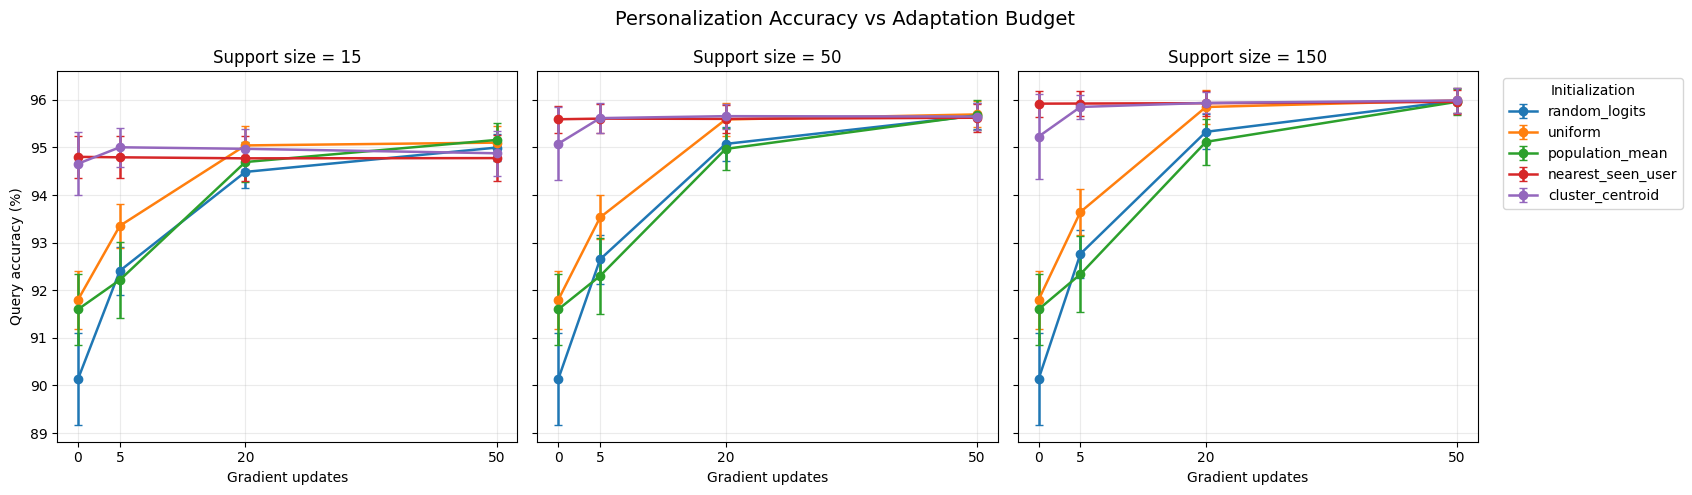

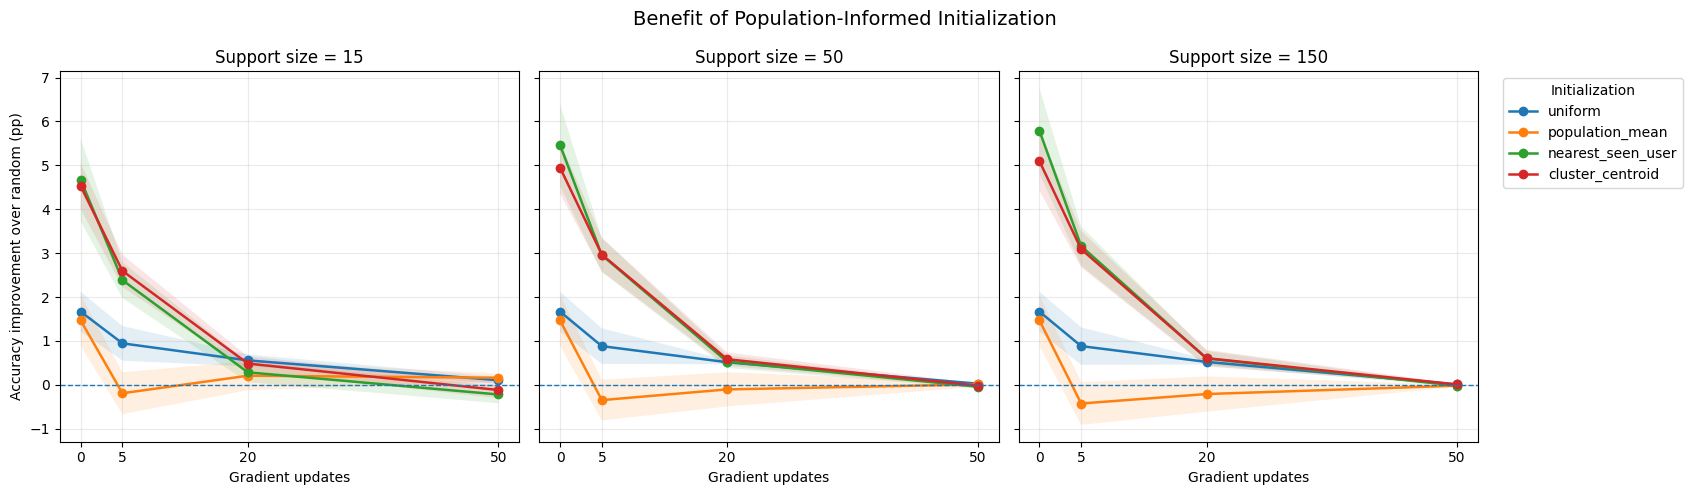

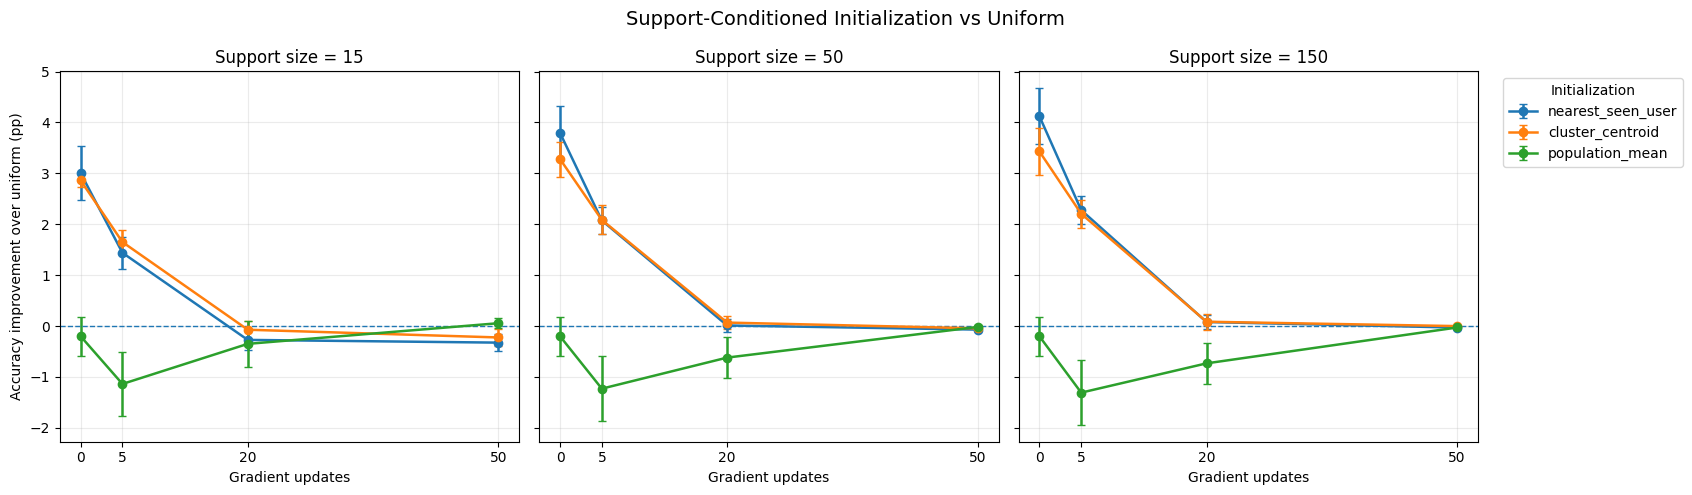


FINAL ANALYSIS COMPLETE
Accuracy summary:
/content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2/results/final_accuracy_summary.csv

Paired comparison vs random:
/content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2/results/corrected_improvement_over_random.csv

Paired comparison vs uniform:
/content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2/results/improvement_over_uniform.csv

Figures:
figure1_accuracy_vs_updates.png
figure2_improvement_over_random.png
figure3_improvement_over_uniform.png


In [ ]:
# ============================================================
# CELL 11: FINAL STATISTICS AND FIGURES
# ============================================================

import matplotlib.pyplot as plt
from scipy.stats import t

PLOT_DIR = RESULTS_DIR / "figures"
PLOT_DIR.mkdir(parents=True, exist_ok=True)

METHODS = [
    "random_logits",
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

# ------------------------------------------------------------
# 1. VALIDATE DATA
# ------------------------------------------------------------

assert len(all_results) == 300
assert all_results["seed"].nunique() == 5
assert all_results["initialization"].nunique() == 5

assert not all_results.duplicated(
    ["seed", "support_size", "initialization", "updates"]
).any()

print("Dataset verified: 300 observations.")


# ------------------------------------------------------------
# 2. AGGREGATE ABSOLUTE ACCURACY
# ------------------------------------------------------------

accuracy_summary = (
    all_results
    .groupby(["support_size", "initialization", "updates"])
    ["mean_query_accuracy"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

accuracy_summary["accuracy_mean_pct"] = (
    accuracy_summary["mean"] * 100
)

accuracy_summary["accuracy_std_pp"] = (
    accuracy_summary["std"] * 100
)

accuracy_summary = accuracy_summary.drop(
    columns=["mean", "std"]
).rename(columns={"count": "num_seeds"})


# ------------------------------------------------------------
# 3. PAIRED IMPROVEMENT HELPER
# ------------------------------------------------------------

def paired_summary(pivot, methods, baseline):

    rows = []

    for n in SUPPORT_SIZES:
        for updates in UPDATE_BUDGETS + [0]:

            for method in methods:

                if method == baseline:
                    continue

                values = (
                    pivot.xs(
                        (n, updates),
                        level=("support_size", "updates")
                    )[method]
                    -
                    pivot.xs(
                        (n, updates),
                        level=("support_size", "updates")
                    )[baseline]
                ) * 100

                values = values.dropna().to_numpy()

                count = len(values)
                mean = values.mean()
                sd = values.std(ddof=1)
                se = sd / np.sqrt(count)

                critical_t = t.ppf(0.975, count - 1)
                margin = critical_t * se

                rows.append({
                    "support_size": n,
                    "updates": updates,
                    "initialization": method,
                    "mean_improvement_pp": mean,
                    "std_across_seeds_pp": sd,
                    "ci95_lower": mean - margin,
                    "ci95_upper": mean + margin,
                    "positive_seeds": int((values > 0).sum()),
                    "total_seeds": count
                })

    return pd.DataFrame(rows)


paired_pivot = all_results.pivot_table(
    index=["seed", "support_size", "updates"],
    columns="initialization",
    values="mean_query_accuracy"
)

# Compare against the original random-logit distribution.
vs_random = paired_summary(
    paired_pivot,
    METHODS,
    "random_logits"
)

# Compare against uniform initialization.
vs_uniform = paired_summary(
    paired_pivot,
    [
        "population_mean",
        "nearest_seen_user",
        "cluster_centroid"
    ],
    "uniform"
)

# ------------------------------------------------------------
# 4. SAVE CORRECTED TABLES
# ------------------------------------------------------------

accuracy_summary.to_csv(
    RESULTS_DIR / "final_accuracy_summary.csv",
    index=False
)

vs_random.to_csv(
    RESULTS_DIR / "corrected_improvement_over_random.csv",
    index=False
)

vs_uniform.to_csv(
    RESULTS_DIR / "improvement_over_uniform.csv",
    index=False
)

print("\nPAIRED IMPROVEMENT OVER RANDOM LOGITS")
display(vs_random.round(3))

print("\nPAIRED IMPROVEMENT OVER UNIFORM")
display(vs_uniform.round(3))


# ------------------------------------------------------------
# 5. FIGURE 1: ACCURACY VS UPDATE BUDGET
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

plot_methods = [
    "random_logits",
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

for ax, n in zip(axes, SUPPORT_SIZES):

    for method in plot_methods:

        subset = accuracy_summary[
            (accuracy_summary["support_size"] == n) &
            (accuracy_summary["initialization"] == method)
        ].sort_values("updates")

        x = subset["updates"].to_numpy()
        y = subset["accuracy_mean_pct"].to_numpy()
        sd = subset["accuracy_std_pp"].to_numpy()

        # 95% confidence interval across five seeds.
        ci = t.ppf(0.975, 4) * sd / np.sqrt(5)

        ax.errorbar(
            x, y,
            yerr=ci,
            marker="o",
            capsize=3,
            linewidth=1.8,
            label=method
        )

    ax.set_title(f"Support size = {n}")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks([0, 5, 20, 50])
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Query accuracy (%)")
axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Personalization Accuracy vs Adaptation Budget",
    fontsize=14
)

plt.tight_layout()

fig.savefig(
    PLOT_DIR / "figure1_accuracy_vs_updates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 6. FIGURE 2: ADVANTAGE OVER RANDOM INITIALIZATION
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

comparison_methods = [
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

for ax, n in zip(axes, SUPPORT_SIZES):

    for method in comparison_methods:

        subset = vs_random[
            (vs_random["support_size"] == n) &
            (vs_random["initialization"] == method)
        ].sort_values("updates")

        x = subset["updates"].to_numpy()
        y = subset["mean_improvement_pp"].to_numpy()

        lower = subset["ci95_lower"].to_numpy()
        upper = subset["ci95_upper"].to_numpy()

        ax.plot(
            x, y,
            marker="o",
            linewidth=1.8,
            label=method
        )

        ax.fill_between(
            x, lower, upper,
            alpha=0.12
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"Support size = {n}")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks([0, 5, 20, 50])
    ax.grid(alpha=0.25)

axes[0].set_ylabel(
    "Accuracy improvement over random (pp)"
)

axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Benefit of Population-Informed Initialization",
    fontsize=14
)

plt.tight_layout()

fig.savefig(
    PLOT_DIR / "figure2_improvement_over_random.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 7. FIGURE 3: SELECTED INITIALIZATIONS VS UNIFORM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 5),
    sharey=True
)

selected_methods = [
    "nearest_seen_user",
    "cluster_centroid",
    "population_mean"
]

for ax, n in zip(axes, SUPPORT_SIZES):

    for method in selected_methods:

        subset = vs_uniform[
            (vs_uniform["support_size"] == n) &
            (vs_uniform["initialization"] == method)
        ].sort_values("updates")

        x = subset["updates"].to_numpy()
        y = subset["mean_improvement_pp"].to_numpy()

        ax.errorbar(
            x, y,
            yerr=[
                y - subset["ci95_lower"].to_numpy(),
                subset["ci95_upper"].to_numpy() - y
            ],
            marker="o",
            capsize=3,
            linewidth=1.8,
            label=method
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"Support size = {n}")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks([0, 5, 20, 50])
    ax.grid(alpha=0.25)

axes[0].set_ylabel(
    "Accuracy improvement over uniform (pp)"
)

axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Support-Conditioned Initialization vs Uniform",
    fontsize=14
)

plt.tight_layout()

fig.savefig(
    PLOT_DIR / "figure3_improvement_over_uniform.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. EXPORT FINAL EXPERIMENT PACKAGE
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL ANALYSIS COMPLETE")
print("=" * 75)

print("Accuracy summary:")
print(RESULTS_DIR / "final_accuracy_summary.csv")

print("\nPaired comparison vs random:")
print(RESULTS_DIR / "corrected_improvement_over_random.csv")

print("\nPaired comparison vs uniform:")
print(RESULTS_DIR / "improvement_over_uniform.csv")

print("\nFigures:")
for path in sorted(PLOT_DIR.glob("*.png")):
    print(path.name)


CENTROID WITHOUT GRADIENT UPDATES VS ADAPTED BASELINES


,support_size,comparison,baseline,baseline_updates,centroid_accuracy_pct,baseline_accuracy_pct,centroid_minus_baseline_pp,ci95_lower,ci95_upper,centroid_wins,total_seeds
0,5,Centroid_0_vs_random_logits_5,random_logits,5,94.071,92.085,1.986,1.517,2.454,5,5
1,5,Centroid_0_vs_random_logits_20,random_logits,20,94.071,93.800,0.271,-0.256,0.798,4,5
2,5,Centroid_0_vs_random_logits_50,random_logits,50,94.071,94.212,-0.141,-0.669,0.387,2,5
3,5,Centroid_0_vs_uniform_5,uniform,5,94.071,93.105,0.966,0.628,1.304,5,5
4,5,Centroid_0_vs_uniform_20,uniform,20,94.071,94.445,-0.374,-1.004,0.256,0,5
5,5,Centroid_0_vs_uniform_50,uniform,50,94.071,94.420,-0.349,-0.987,0.290,1,5
6,15,Centroid_0_vs_random_logits_5,random_logits,5,94.657,92.408,2.249,2.021,2.477,5,5
7,15,Centroid_0_vs_random_logits_20,random_logits,20,94.657,94.486,0.172,-0.386,0.729,3,5
8,15,Centroid_0_vs_random_logits_50,random_logits,50,94.657,94.996,-0.339,-0.873,0.196,0,5
9,15,Centroid_0_vs_uniform_5,uniform,5,94.657,93.352,1.305,0.884,1.726,5,5



FIVE-EXAMPLE COMPARISON


,support_size,comparison,baseline,baseline_updates,centroid_accuracy_pct,baseline_accuracy_pct,centroid_minus_baseline_pp,ci95_lower,ci95_upper,centroid_wins,total_seeds
0,5,Centroid_0_vs_random_logits_5,random_logits,5,94.071,92.085,1.986,1.517,2.454,5,5
1,5,Centroid_0_vs_random_logits_20,random_logits,20,94.071,93.800,0.271,-0.256,0.798,4,5
2,5,Centroid_0_vs_random_logits_50,random_logits,50,94.071,94.212,-0.141,-0.669,0.387,2,5
3,5,Centroid_0_vs_uniform_5,uniform,5,94.071,93.105,0.966,0.628,1.304,5,5
4,5,Centroid_0_vs_uniform_20,uniform,20,94.071,94.445,-0.374,-1.004,0.256,0,5
5,5,Centroid_0_vs_uniform_50,uniform,50,94.071,94.420,-0.349,-0.987,0.290,1,5


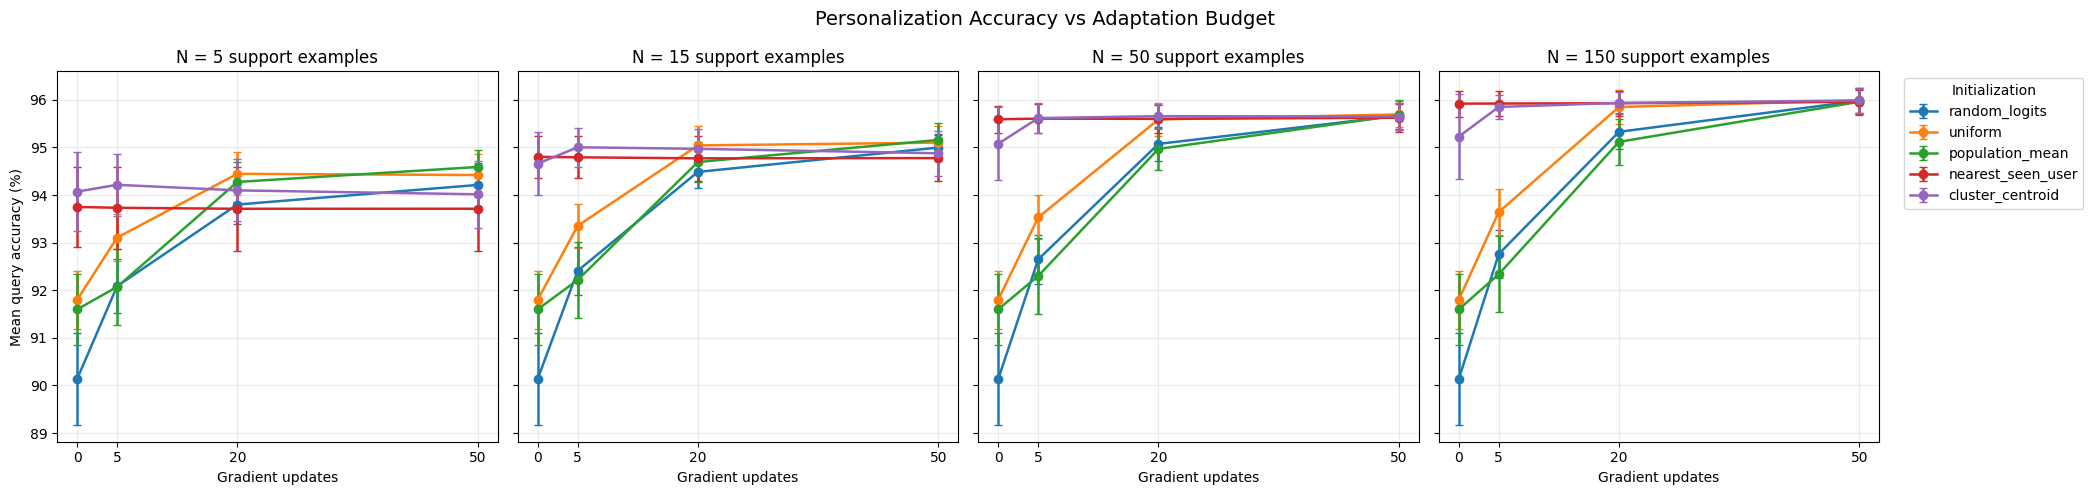

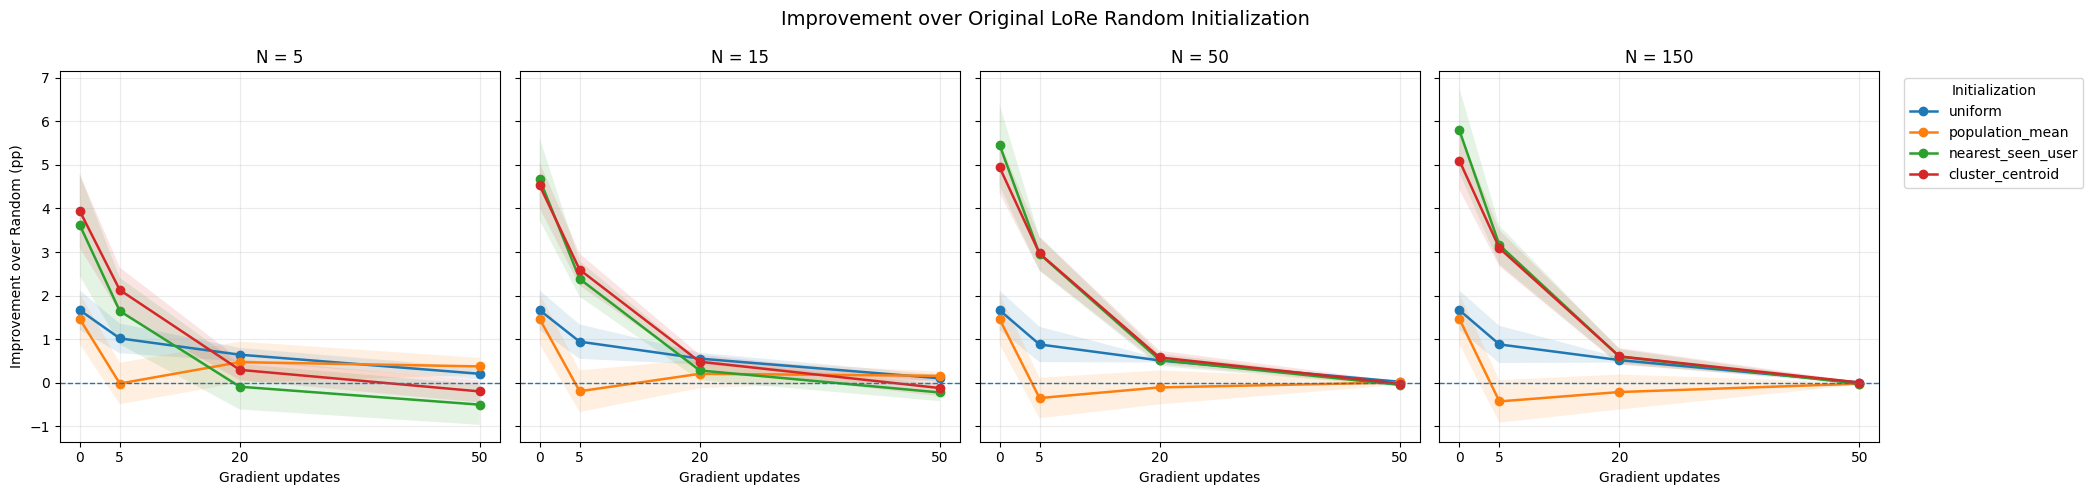

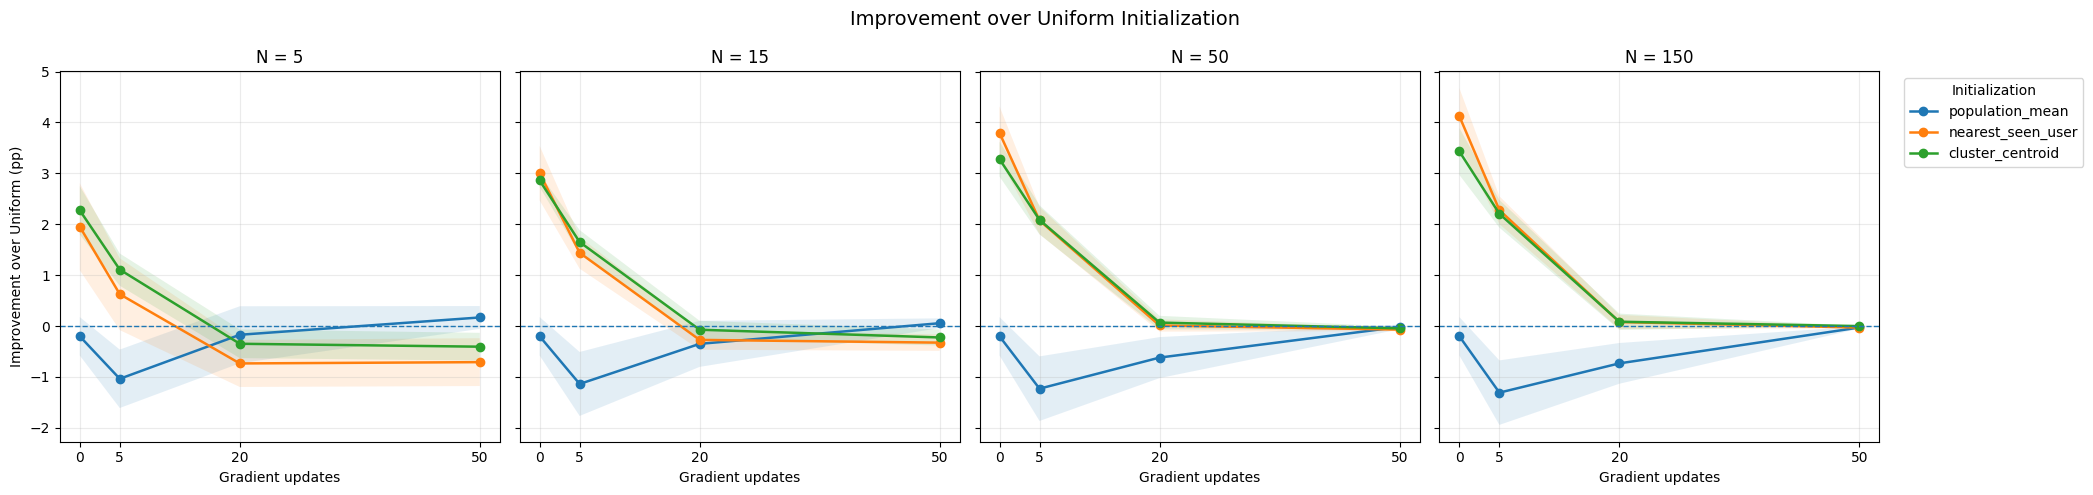

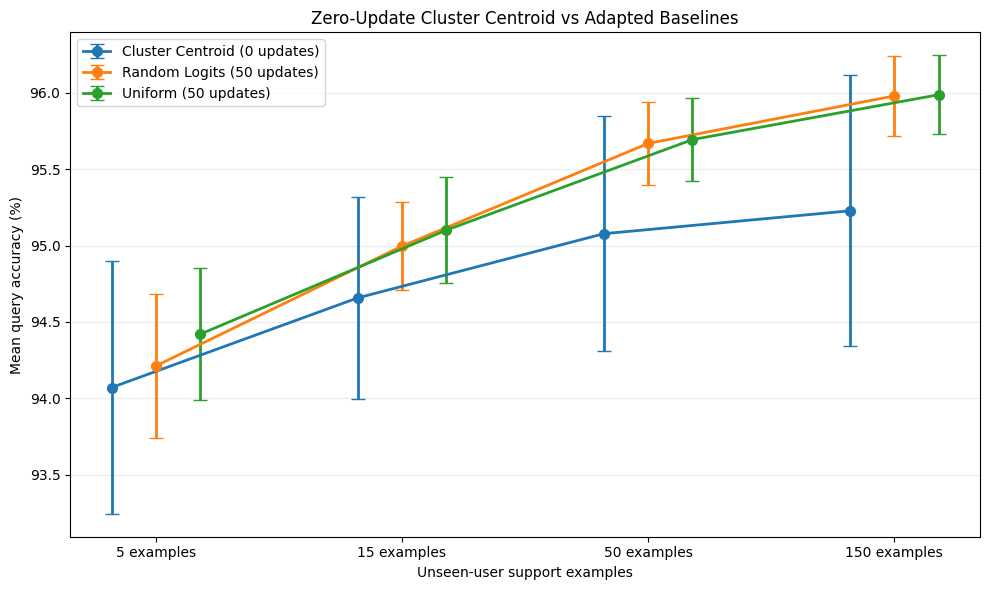


FIGURES AND DIRECT COMPARISONS UPDATED
Direct comparison CSV:
/content/drive/MyDrive/LoRe/FewShot_Initialization/PersonalLLM_v2/results/centroid_zero_vs_adapted_baselines.csv

Figure files:
figure1_accuracy_vs_updates.png
figure2_improvement_over_random.png
figure3_improvement_over_uniform.png
figure4_centroid_without_gradient_updates.png


In [ ]:
# ============================================================
# CELL 13: ZERO-UPDATE CENTROID VS ADAPTED BASELINES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import t

SUPPORT_SIZES = [5, 15, 50, 150]
UPDATE_BUDGETS = [0, 5, 20, 50]

# ------------------------------------------------------------
# 1. VERIFY FINAL RESULTS
# ------------------------------------------------------------

assert len(all_results) == 400
assert set(all_results["support_size"].unique()) == set(SUPPORT_SIZES)
assert all_results["seed"].nunique() == 5

pivot = all_results.pivot_table(
    index=["seed", "support_size"],
    columns=["initialization", "updates"],
    values="mean_query_accuracy"
)

METHODS = [
    "random_logits",
    "uniform",
    "population_mean",
    "nearest_seen_user",
    "cluster_centroid"
]

# ------------------------------------------------------------
# 2. PAIRED COMPARISON: CENTROID AT STEP 0 VS TRAINED BASELINES
# ------------------------------------------------------------

rows = []

for n in SUPPORT_SIZES:

    data = pivot.xs(n, level="support_size")

    centroid_zero = data[("cluster_centroid", 0)]

    for baseline in ["random_logits", "uniform"]:

        for budget in [5, 20, 50]:

            baseline_accuracy = data[(baseline, budget)]

            # Positive difference means zero-update centroid is better.
            delta = (
                centroid_zero - baseline_accuracy
            ).to_numpy() * 100

            mean = delta.mean()
            std = delta.std(ddof=1)
            se = std / np.sqrt(len(delta))
            margin = t.ppf(0.975, len(delta) - 1) * se

            rows.append({
                "support_size": n,
                "comparison": f"Centroid_0_vs_{baseline}_{budget}",
                "baseline": baseline,
                "baseline_updates": budget,
                "centroid_accuracy_pct": centroid_zero.mean() * 100,
                "baseline_accuracy_pct": baseline_accuracy.mean() * 100,
                "centroid_minus_baseline_pp": mean,
                "ci95_lower": mean - margin,
                "ci95_upper": mean + margin,
                "centroid_wins": int((delta > 0).sum()),
                "total_seeds": len(delta)
            })

direct_comparison = pd.DataFrame(rows)

direct_comparison.to_csv(
    RESULTS_DIR / "centroid_zero_vs_adapted_baselines.csv",
    index=False
)

print("\nCENTROID WITHOUT GRADIENT UPDATES VS ADAPTED BASELINES")
display(direct_comparison.round(3))

print("\nFIVE-EXAMPLE COMPARISON")
display(
    direct_comparison[
        direct_comparison["support_size"] == 5
    ].round(3)
)


# ------------------------------------------------------------
# 3. HELPER: MEAN AND 95% CI ACROSS FIVE SEEDS
# ------------------------------------------------------------

def seed_mean_ci(values):

    values = np.asarray(values, dtype=float)

    mean = values.mean()
    se = values.std(ddof=1) / np.sqrt(len(values))
    margin = t.ppf(0.975, len(values) - 1) * se

    return mean, margin


# ------------------------------------------------------------
# 4. UPDATE FIGURE 1: ACCURACY VS ADAPTATION BUDGET
# ------------------------------------------------------------

plot_dir = RESULTS_DIR / "figures"
plot_dir.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    1, 4, figsize=(21, 5), sharey=True
)

for ax, n in zip(axes, SUPPORT_SIZES):

    for method in METHODS:

        means, errors = [], []

        for step in UPDATE_BUDGETS:

            values = all_results[
                (all_results["support_size"] == n) &
                (all_results["initialization"] == method) &
                (all_results["updates"] == step)
            ]["mean_query_accuracy"].to_numpy() * 100

            mean, ci = seed_mean_ci(values)
            means.append(mean)
            errors.append(ci)

        ax.errorbar(
            UPDATE_BUDGETS,
            means,
            yerr=errors,
            marker="o",
            capsize=3,
            linewidth=1.8,
            label=method
        )

    ax.set_title(f"N = {n} support examples")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks(UPDATE_BUDGETS)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Mean query accuracy (%)")
axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Personalization Accuracy vs Adaptation Budget",
    fontsize=14
)

plt.tight_layout()
fig.savefig(
    plot_dir / "figure1_accuracy_vs_updates.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 5. UPDATE FIGURE 2: IMPROVEMENT OVER RANDOM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 4, figsize=(21, 5), sharey=True
)

for ax, n in zip(axes, SUPPORT_SIZES):

    data = pivot.xs(n, level="support_size")

    for method in [
        "uniform",
        "population_mean",
        "nearest_seen_user",
        "cluster_centroid"
    ]:

        means, lower, upper = [], [], []

        for step in UPDATE_BUDGETS:

            delta = (
                data[(method, step)] -
                data[("random_logits", step)]
            ).to_numpy() * 100

            mean, ci = seed_mean_ci(delta)

            means.append(mean)
            lower.append(mean - ci)
            upper.append(mean + ci)

        ax.plot(
            UPDATE_BUDGETS,
            means,
            marker="o",
            linewidth=1.8,
            label=method
        )

        ax.fill_between(
            UPDATE_BUDGETS,
            lower,
            upper,
            alpha=0.12
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"N = {n}")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks(UPDATE_BUDGETS)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Improvement over Random (pp)")
axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Improvement over Original LoRe Random Initialization",
    fontsize=14
)

plt.tight_layout()
fig.savefig(
    plot_dir / "figure2_improvement_over_random.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 6. UPDATE FIGURE 3: IMPROVEMENT OVER UNIFORM
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 4, figsize=(21, 5), sharey=True
)

for ax, n in zip(axes, SUPPORT_SIZES):

    data = pivot.xs(n, level="support_size")

    for method in [
        "population_mean",
        "nearest_seen_user",
        "cluster_centroid"
    ]:

        means, lower, upper = [], [], []

        for step in UPDATE_BUDGETS:

            delta = (
                data[(method, step)] -
                data[("uniform", step)]
            ).to_numpy() * 100

            mean, ci = seed_mean_ci(delta)

            means.append(mean)
            lower.append(mean - ci)
            upper.append(mean + ci)

        ax.plot(
            UPDATE_BUDGETS,
            means,
            marker="o",
            linewidth=1.8,
            label=method
        )

        ax.fill_between(
            UPDATE_BUDGETS,
            lower,
            upper,
            alpha=0.12
        )

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_title(f"N = {n}")
    ax.set_xlabel("Gradient updates")
    ax.set_xticks(UPDATE_BUDGETS)
    ax.grid(alpha=0.25)

axes[0].set_ylabel("Improvement over Uniform (pp)")
axes[-1].legend(
    title="Initialization",
    bbox_to_anchor=(1.04, 1),
    loc="upper left"
)

fig.suptitle(
    "Improvement over Uniform Initialization",
    fontsize=14
)

plt.tight_layout()
fig.savefig(
    plot_dir / "figure3_improvement_over_uniform.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 7. NEW FIGURE 4: CAN CENTROID SKIP GRADIENT ADAPTATION?
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

series = [
    ("cluster_centroid", 0, "Cluster Centroid (0 updates)"),
    ("random_logits", 50, "Random Logits (50 updates)"),
    ("uniform", 50, "Uniform (50 updates)")
]

x = np.arange(len(SUPPORT_SIZES))
offsets = [-0.18, 0, 0.18]

for (method, step, label), offset in zip(series, offsets):

    means, errors = [], []

    for n in SUPPORT_SIZES:

        values = all_results[
            (all_results["support_size"] == n) &
            (all_results["initialization"] == method) &
            (all_results["updates"] == step)
        ]["mean_query_accuracy"].to_numpy() * 100

        mean, ci = seed_mean_ci(values)

        means.append(mean)
        errors.append(ci)

    ax.errorbar(
        x + offset,
        means,
        yerr=errors,
        marker="o",
        capsize=5,
        linewidth=2,
        markersize=7,
        label=label
    )

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{n} examples" for n in SUPPORT_SIZES]
)

ax.set_ylabel("Mean query accuracy (%)")
ax.set_xlabel("Unseen-user support examples")

ax.set_title(
    "Zero-Update Cluster Centroid vs Adapted Baselines"
)

ax.grid(axis="y", alpha=0.25)
ax.legend()

plt.tight_layout()

fig.savefig(
    plot_dir / "figure4_centroid_without_gradient_updates.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ------------------------------------------------------------
# 8. SAVE FINAL OUTPUTS
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FIGURES AND DIRECT COMPARISONS UPDATED")
print("=" * 75)

print("Direct comparison CSV:")
print(RESULTS_DIR / "centroid_zero_vs_adapted_baselines.csv")

print("\nFigure files:")
for path in sorted(plot_dir.glob("*.png")):
    print(path.name)

## 6. Analysis & Discussion

### Figure Explanations

- **Figure 1 (Accuracy vs. Adaptation Budget):** Shows query accuracy across gradient updates for different support sizes. Population-informed initializations, particularly Cluster Centroid and Nearest Seen User, achieve stronger initial accuracy, while Random Logits and Uniform progressively catch up with adaptation.

- **Figure 2 (Improvement over Random Logits):** Shows the benefit of population-informed initialization over the original LoRe initialization. Cluster Centroid achieves substantial gains at initialization and retains a 2–3 percentage-point advantage after five gradient updates.

- **Figure 3 (Improvement over Uniform):** Isolates the contribution of support-conditioned selection over equal weighting of the reward bases. The consistent early gains demonstrate the value of using unseen-user support feedback to select a representative preference profile.

### Core Findings

- **Immediate Personalization (Step 0):** Cluster Centroid improves query accuracy over original Random Logits by **+4.53 pp (N=15), +4.95 pp (N=50), and +5.10 pp (N=150)**. Compared with Uniform initialization, the corresponding gains are **+2.86 pp, +3.28 pp, and +3.43 pp**.

- **Early Adaptation (Step 5):** Cluster Centroid retains substantial improvements over Random Logits of **+2.60 pp, +2.97 pp, and +3.09 pp** for support sizes 15, 50 and 150, respectively. Its advantage over Uniform also remains positive, ranging from **+1.65 pp to +2.21 pp**.

- **Convergence with Adaptation:** By 20 updates, the performance differences become substantially smaller. By 50 updates, all initialization strategies achieve nearly equivalent query accuracy. This suggests that population-informed initialization primarily accelerates personalization rather than improving its eventual performance.

- **Population Mean:** Although Population Mean provides a modest improvement over Random Logits before adaptation, it generally underperforms support-conditioned methods. This highlights the importance of selecting preference profiles based on individual support feedback rather than relying solely on population averages.

- **Scalability of Cluster Centroid:** Instead of evaluating all 1,000 seen-user preference vectors for every unseen user, Cluster Centroid selects among only five representative centroids. This offers a computationally efficient alternative to exhaustive nearest-user selection while retaining strong personalization performance.

### Discussion

The results demonstrate that leveraging population structure can substantially improve few-shot personalization when the adaptation budget is limited. In particular, Cluster Centroid provides a strong balance between initialization quality and candidate-selection efficiency. Its advantage is most pronounced with limited adaptation, while conventional optimization progressively closes the performance gap.

The experiment uses five random seeds and a fixed Dirichlet preference setting (α = 0.1). Further evaluation across additional preference distributions and support sizes would help establish the generality of these findings.

## Conclusion

We investigate support-conditioned initialization for few-shot personalization in low-rank reward models. By clustering learned preference profiles from previously observed users, we construct a compact set of representative initializations and select the most suitable centroid using an unseen user's support feedback. Cluster Centroid achieves up to a **5.10 percentage-point improvement over the original LoRe random-logit initialization** and a **3.43 percentage-point improvement over Uniform initialization**, even before gradient adaptation. These gains remain substantial after five adaptation updates, demonstrating improved early personalization with limited user feedback. Furthermore, selecting among only five cluster centroids provides a scalable alternative to searching across the entire seen-user population. As adaptation progresses, the performance differences diminish, indicating that population-informed initialization primarily accelerates personalization rather than improving its eventual accuracy. Overall, the findings highlight the value of exploiting population structure for efficient few-shot personalization when inference-time adaptation budgets are limited.